<a href="https://colab.research.google.com/github/praveen24sriv/Deepfake-video-detection-system/blob/feat%2Fpreprocessing-ffpp/preprocessing/FFpp_c40_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FaceForensics++ (C40) — Preprocessing Pipeline
DeepGuard AI · Spatiotemporal deepfake video detection

**Input:** 6,000 FF++ c40 videos (1,000 real + 5 manipulation methods) on Google Drive.
**Output:** per-video sequences of 32 face crops (224×224), a `manifest.csv`, and report charts.

Pipeline: official video-level splits → evenly spaced frame sampling → MTCNN face detection → margin crop → quality stats → manifest.

> Runtime: **GPU** (Runtime → Change runtime type → T4 GPU). Full run ≈ 45–90 min; it resumes if interrupted.

In [12]:
# Setup
from google.colab import drive
drive.mount('/content/drive')

!pip install -q facenet-pytorch --no-deps   # --no-deps keeps Colab's torch untouched

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
# 2. edit paths here only
from pathlib import Path

DRIVE_SRC   = Path('/content/drive/MyDrive/FFpp_c40')   # where the 6,000 videos were unzipped
LOCAL_SRC   = Path('/content/ffpp_c40')                 # local copy (Drive reads are slow)
LOCAL_OUT   = Path('/content/ffpp_c40_faces')           # crops written here first
DRIVE_OUT   = Path('/content/drive/MyDrive/FFpp_c40_processed')

N_FRAMES    = 32       # frames sampled per video (training can use 16 of these)
CROP_SIZE   = 224
MARGIN      = 1.3      # face box scale factor (keeps hairline/jaw boundary, where blending artifacts sit)
TRAIN_METHODS = ['Deepfakes', 'Face2Face', 'FaceSwap', 'NeuralTextures']   # standard FF++ benchmark
HELDOUT_METHODS = ['FaceShifter']                                          # unseen-method test only
REAL_DIR    = 'real'

LOCAL_OUT.mkdir(parents=True, exist_ok=True)
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

In [14]:
#  Copy videos to local disk (one-time, ~1.4 GB) — much faster than reading Drive per frame
!rsync -a --info=progress2 "{DRIVE_SRC}/" "{LOCAL_SRC}/"

videos = sorted(LOCAL_SRC.rglob('*.mp4'))
from collections import Counter
print(len(videos), 'videos')
print(Counter(v.parent.name for v in videos))

              0   0%    0.00kB/s    0:00:00 (xfr#0, to-chk=0/6013)
6000 videos
Counter({'Deepfakes': 1000, 'Face2Face': 1000, 'FaceShifter': 1000, 'FaceSwap': 1000, 'NeuralTextures': 1000, 'real': 1000})


## Official video-level splits
FF++ ships `train/val/test.json` (720/140/140 pairs). A pair `["071","054"]` puts real videos 071 and 054 **and** every fake `071_054` / `054_071` in the same split.
Using these instead of a random frame split prevents identity leakage between train and test (the Celeb-DF notebook's 80/10/10 frame split would inflate test accuracy here).

In [15]:
# Official splits
import json, urllib.request

SPLIT_URL = 'https://raw.githubusercontent.com/ondyari/FaceForensics/master/dataset/splits/{}.json'
id2split = {}
for split in ['train', 'val', 'test']:
    pairs = json.loads(urllib.request.urlopen(SPLIT_URL.format(split)).read())
    for a, b in pairs:
        for key in (a, b, f'{a}_{b}', f'{b}_{a}'):
            id2split[key] = split
    print(split, len(pairs), 'pairs')

def video_meta(path):
    method = path.parent.name
    vid = path.stem
    label = 0 if method == REAL_DIR else 1
    return dict(video_id=vid, method=method, label=label, split=id2split.get(vid, 'unknown'),
                src=str(path))

import pandas as pd
meta = pd.DataFrame([video_meta(v) for v in videos])
print(pd.crosstab(meta.method, meta.split, margins=True))
assert (meta.split == 'unknown').sum() == 0, 'some videos are not in the official splits'

train 360 pairs
val 70 pairs
test 70 pairs
split           test  train  val   All
method                                
Deepfakes        140    720  140  1000
Face2Face        140    720  140  1000
FaceShifter      140    720  140  1000
FaceSwap         140    720  140  1000
NeuralTextures   140    720  140  1000
real             140    720  140  1000
All              840   4320  840  6000


## Frame sampling + face cropping
- **Sampling:** 32 evenly spaced frames across the whole clip, kept **in order** (the temporal model needs sequences, not loose images).
- **Detection:** MTCNN on GPU, all 32 frames of a video in one batch. Largest face per frame; if a frame has no detection, the previous frame's box is reused so the sequence stays complete.
- **Crop:** square box scaled by 1.3× around the face centre, clamped to the frame, resized to 224×224.

In [16]:
#  Pipeline functions
import cv2, numpy as np, torch
from facenet_pytorch import MTCNN

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
mtcnn = MTCNN(keep_all=True, device=device, select_largest=True, post_process=False)

def sample_frames(path, n=N_FRAMES):
    """Return n evenly spaced RGB frames (in temporal order) and their indices."""
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release(); return [], []
    wanted = set(np.linspace(0, total - 1, num=min(n, total)).round().astype(int).tolist())
    frames, idxs, i = [], [], 0
    while True:
        ok = cap.grab()
        if not ok: break
        if i in wanted:
            ok, f = cap.retrieve()
            if ok:
                frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)); idxs.append(i)
        i += 1
        if i > max(wanted): break
    cap.release()
    return frames, idxs

def square_box(box, w, h, margin=MARGIN):
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = max(x2 - x1, y2 - y1) * margin
    side = min(side, w, h)
    x1 = int(np.clip(cx - side / 2, 0, w - side)); y1 = int(np.clip(cy - side / 2, 0, h - side))
    return x1, y1, x1 + int(side), y1 + int(side)

def largest(boxes):
    if boxes is None or len(boxes) == 0: return None
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return boxes[int(np.argmax(areas))]

def crop_video(frames):
    """Detect faces in all frames (one batch) and return crops + detection stats."""
    h, w = frames[0].shape[:2]
    boxes, _ = mtcnn.detect(frames)
    crops, last, n_detected = [], None, 0
    for f, b in zip(frames, boxes):
        b = largest(b)
        if b is not None:
            last, n_detected = b, n_detected + 1
        if last is None:
            continue                       # no face yet -> skip until first detection
        x1, y1, x2, y2 = square_box(last, w, h)
        crops.append(cv2.resize(f[y1:y2, x1:x2], (CROP_SIZE, CROP_SIZE), interpolation=cv2.INTER_AREA))
    # back-fill leading frames that came before the first detection
    if crops and len(crops) < len(frames):
        crops = [crops[0]] * (len(frames) - len(crops)) + crops
    return crops, n_detected

def blur_score(rgb):
    return cv2.Laplacian(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var()

device: cuda


In [17]:
# Run on every video (resumable + saves progress to Drive every 500 new videos)
from tqdm.auto import tqdm
import subprocess

PARTIAL = DRIVE_OUT / 'faces_partial.tar'
CKPT_EVERY = 500

def save_checkpoint():
    subprocess.run(['tar', '-cf', str(PARTIAL), '-C', str(LOCAL_OUT), '.'], check=True)

# restore progress after a disconnect
if PARTIAL.exists() and not any(LOCAL_OUT.iterdir()):
    print('Restoring previous progress from Drive...')
    subprocess.run(['tar', '-xf', str(PARTIAL), '-C', str(LOCAL_OUT)], check=True)

rows, new_since_ckpt = [], 0
for r in tqdm(meta.itertuples(), total=len(meta)):
    out_dir = LOCAL_OUT / r.method / r.video_id
    done = out_dir.exists() and len(list(out_dir.glob('*.jpg'))) > 0
    if done:
        saved = sorted(out_dir.glob('*.jpg'))
        n_saved, n_det = len(saved), None
        blurs = [blur_score(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)) for p in saved]
    else:
        frames, _ = sample_frames(r.src)
        if not frames:
            rows.append(dict(r._asdict(), n_frames=0, n_detected=0, blur_mean=np.nan, status='unreadable')); continue
        crops, n_det = crop_video(frames)
        if not crops:
            rows.append(dict(r._asdict(), n_frames=0, n_detected=0, blur_mean=np.nan, status='no_face')); continue
        out_dir.mkdir(parents=True, exist_ok=True)
        for k, c in enumerate(crops):
            cv2.imwrite(str(out_dir / f'{k:02d}.jpg'), cv2.cvtColor(c, cv2.COLOR_RGB2BGR),
                        [cv2.IMWRITE_JPEG_QUALITY, 95])
        n_saved = len(crops)
        blurs = [blur_score(c) for c in crops]
        new_since_ckpt += 1
    rows.append(dict(r._asdict(), n_frames=n_saved, n_detected=n_det,
                     blur_mean=float(np.mean(blurs)) if blurs else np.nan, status='ok',
                     crops_dir=str((LOCAL_OUT / r.method / r.video_id).relative_to(LOCAL_OUT))))

    if new_since_ckpt >= CKPT_EVERY:
        save_checkpoint()
        tqdm.write(f'  checkpoint saved to Drive ({len(rows)} videos done)')
        new_since_ckpt = 0

save_checkpoint()   # final save
manifest = pd.DataFrame(rows).drop(columns=['Index'], errors='ignore')
print(manifest.status.value_counts())

  0%|          | 0/6000 [00:00<?, ?it/s]

status
ok    6000
Name: count, dtype: int64


## Quality analysis (c40-specific)
The Celeb-DF notebook dropped frames with Laplacian variance < 80. On c40 that would discard most of the dataset, because heavy compression **is** blur — and robustness to it is the project's goal.
So here blur is **measured and reported**, and only extreme outliers (bottom 1%) are flagged, not silently removed.

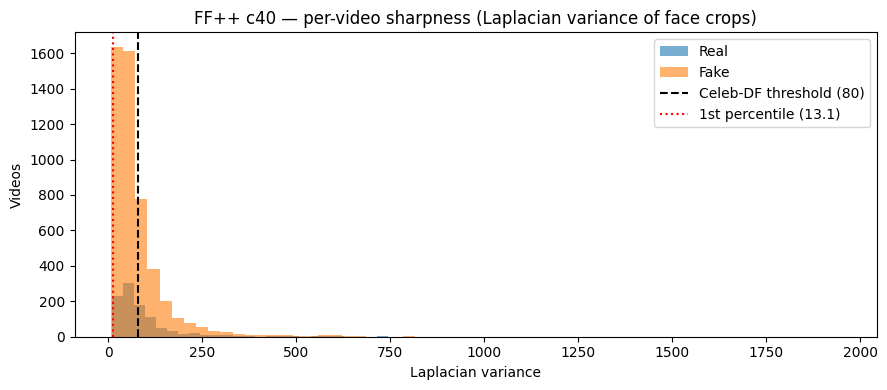

Videos below the old threshold 80: 67.9%
Flagged low quality (bottom 1%): 60


In [18]:
# Quality stats + flags
import matplotlib.pyplot as plt

manifest = manifest.drop(columns=['low_quality'], errors='ignore')   # safe to re-run
ok = manifest[manifest.status == 'ok'].copy()
thr = ok.blur_mean.quantile(0.01)
ok['low_quality'] = ok.blur_mean < thr
manifest = manifest.merge(ok[['video_id', 'method', 'low_quality']], on=['video_id', 'method'], how='left')

fig, ax = plt.subplots(figsize=(9, 4))
for lab, name in [(0, 'Real'), (1, 'Fake')]:
    ax.hist(ok[ok.label == lab].blur_mean, bins=60, alpha=0.6, label=name)
ax.axvline(80, ls='--', c='k', label='Celeb-DF threshold (80)')
ax.axvline(thr, ls=':', c='r', label=f'1st percentile ({thr:.1f})')
ax.set(title='FF++ c40 — per-video sharpness (Laplacian variance of face crops)', xlabel='Laplacian variance', ylabel='Videos')
ax.legend(); plt.tight_layout(); plt.savefig(DRIVE_OUT / 'blur_distribution.png', dpi=150); plt.show()

print(f'Videos below the old threshold 80: {(ok.blur_mean < 80).mean():.1%}')
print(f'Flagged low quality (bottom 1%): {ok.low_quality.sum()}')

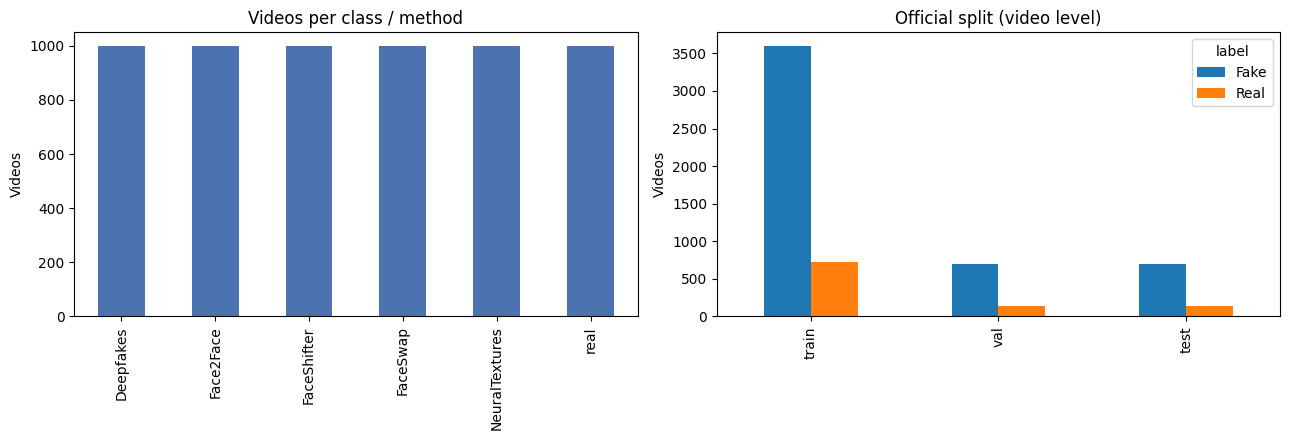

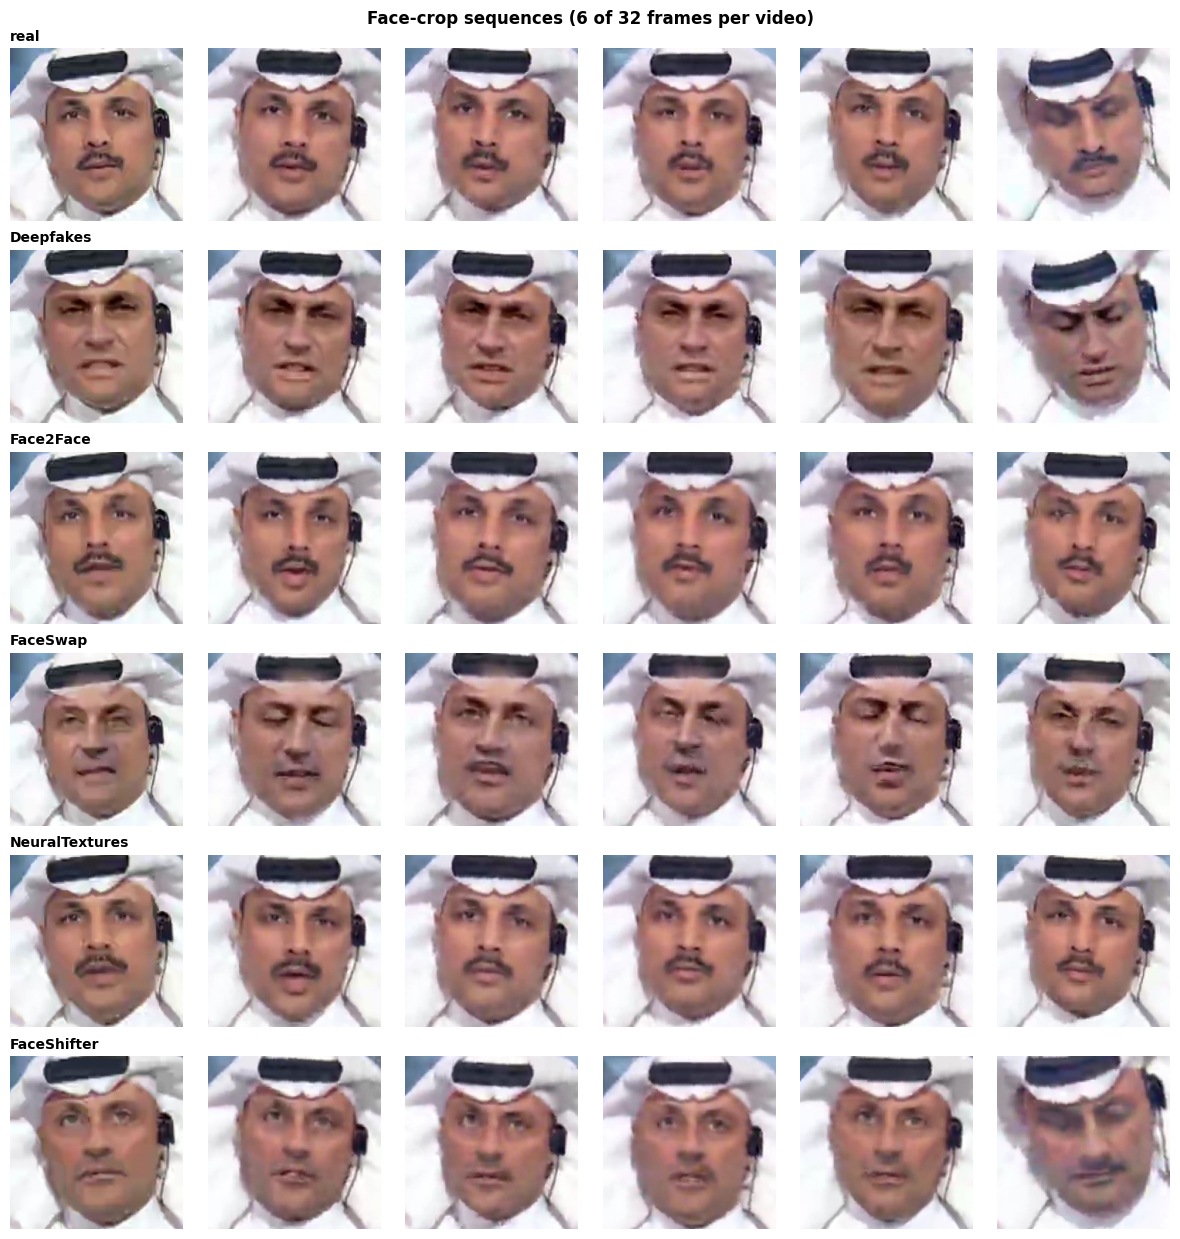

In [19]:
# Report charts: class balance, splits, sample crops
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
manifest[manifest.status == 'ok'].groupby('method').size().plot.bar(ax=axes[0], color='#4C72B0')
axes[0].set(title='Videos per class / method', ylabel='Videos', xlabel='')
pd.crosstab(manifest.split, manifest.label.map({0: 'Real', 1: 'Fake'})).loc[['train', 'val', 'test']].plot.bar(ax=axes[1])
axes[1].set(title='Official split (video level)', ylabel='Videos', xlabel='')
plt.tight_layout(); plt.savefig(DRIVE_OUT / 'dataset_split.png', dpi=150); plt.show()

methods = [REAL_DIR] + TRAIN_METHODS + HELDOUT_METHODS
fig, axes = plt.subplots(len(methods), 6, figsize=(12, 2.1 * len(methods)))
for i, m in enumerate(methods):
    vid_dir = LOCAL_OUT / m / manifest[(manifest.method == m) & (manifest.status == 'ok')].video_id.iloc[0]
    frames = sorted(vid_dir.glob('*.jpg'))
    for j, k in enumerate(np.linspace(0, len(frames) - 1, 6).astype(int)):
        axes[i, j].imshow(plt.imread(frames[k])); axes[i, j].axis('off')
    axes[i, 0].set_title(m, loc='left', fontsize=10, fontweight='bold')
plt.suptitle('Face-crop sequences (6 of 32 frames per video)', fontweight='bold')
plt.tight_layout(); plt.savefig(DRIVE_OUT / 'sample_sequences.png', dpi=150); plt.show()

## Save outputs
- `manifest.csv` — one row per video: `video_id, method, label, split, n_frames, n_detected, blur_mean, low_quality, status, crops_dir`
- `faces.tar` — all crops (`<method>/<video_id>/00.jpg … 31.jpg`). One tar file uploads to Drive far faster than ~190k small JPEGs.
- `use_in_training` = standard 4 methods + real, status ok. FaceShifter rows are kept for the unseen-method test.

In [20]:
# Save manifest + crops to Drive
manifest['use_in_training'] = (manifest.status == 'ok') & manifest.method.isin([REAL_DIR] + TRAIN_METHODS)
manifest['heldout_method']  = manifest.method.isin(HELDOUT_METHODS)
manifest.to_csv(DRIVE_OUT / 'manifest.csv', index=False)

print(manifest[manifest.use_in_training].groupby(['split', 'label']).size().unstack())
!tar -cf "{DRIVE_OUT}/faces.tar" -C "{LOCAL_OUT}" .
!ls -lh "{DRIVE_OUT}"

label    0     1
split           
test   140   560
train  720  2880
val    140   560
total 5.0G
-rw------- 1 root root  54K Oct 10 23:22 blur_distribution.png
-rw------- 1 root root  59K Oct 10 23:22 dataset_split.png
-rw------- 1 root root 2.5G Oct 10 23:22 faces_partial.tar
-rw------- 1 root root 2.5G Oct 10 23:24 faces.tar
-rw------- 1 root root 729K Oct 10 23:22 manifest.csv
-rw------- 1 root root 2.9M Oct 10 23:22 sample_sequences.png


## Reloading in the training notebook
```python
!tar -xf /content/drive/MyDrive/FFpp_c40_processed/faces.tar -C /content/faces
manifest = pd.read_csv('/content/drive/MyDrive/FFpp_c40_processed/manifest.csv')
```
Normalization (resize is already done; ImageNet mean/std) is applied in the training dataloader, so crops on disk stay as plain images.